This notebook contains the complete pipeline for training, evaluating, and comparing ResNet50, DenseNet121 as baselines.

## 1. Imports

In [1]:
import cv2
import os
import numpy as np
import pandas as pd
from math import exp, sqrt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.multiclass import unique_labels
from sklearn.utils import shuffle
import keras
import tensorflow as tf
import time
from datetime import datetime
from PIL import Image
from zipfile import ZipFile
import shutil
import kagglehub

import tensorflow.keras.backend as K
from keras import Input
from keras.models import Model
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import BatchNormalization, Concatenate, Add, DepthwiseConv2D, GlobalAveragePooling2D, SeparableConv2D
from tensorflow.keras.optimizers import SGD, RMSprop, Adam, Adagrad
from keras.layers import Conv2D, MaxPooling2D

from tensorflow.keras.applications import ResNet50, DenseNet121, EfficientNetB0, MobileNetV2
from keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Keras 3 compatibility for model.export
if int(tf.__version__.split('.')[0]) >= 2 and int(tf.__version__.split('.')[1]) >= 15:
    tf.keras.backend.set_image_data_format('channels_last')

METRICS = [
    tf.keras.metrics.CategoricalAccuracy(name='accuracy'),
    tf.keras.metrics.Precision(name='precision'),
    tf.keras.metrics.Recall(name='recall'),
    tf.keras.metrics.AUC(name='auc')
]

# Define the optimizer for all models
LFANET_OPTIMIZER = tf.keras.optimizers.Adam(learning_rate=1e-3)

## 2. Dataset Loading

In [2]:
# Download latest version
path = kagglehub.dataset_download("vibhingupta028/liver-histopathology-fibrosis-ultrasound-images")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'liver-histopathology-fibrosis-ultrasound-images' dataset.
Path to dataset files: /kaggle/input/liver-histopathology-fibrosis-ultrasound-images


## 3. Data Preprocessing

In [3]:
# Define class names
class_names = ['F0', 'F1', 'F2', 'F3', 'F4']
class_to_label = {name: idx for idx, name in enumerate(class_names)}

img_data_list = []
labels = []

# Load images and labels
# Corrected path to account for the nested 'Dataset' directory
dataset_path = os.path.join(path, 'Dataset', 'Dataset')
for dataset in class_names:
    img_list = os.listdir(os.path.join(dataset_path, dataset))
    print(f'Loaded images from dataset-{dataset}, total: {len(img_list)}')

    for img in img_list:
        img_path = os.path.join(dataset_path, dataset, img)
        input_img = cv2.imread(img_path)
        if input_img is None:
            continue
        input_img_resize = cv2.resize(input_img, (128, 128))
        img_data_list.append(input_img_resize)
        labels.append(class_to_label[dataset])  # Use mapped label

# Convert to NumPy arrays and normalize
data = np.array(img_data_list, dtype="float32") / 255.0
labels = np.array(labels)

# One-hot encode labels
num_classes = len(class_names)
labels_one_hot = to_categorical(labels, num_classes)

Loaded images from dataset-F0, total: 2114
Loaded images from dataset-F1, total: 861
Loaded images from dataset-F2, total: 793
Loaded images from dataset-F3, total: 857
Loaded images from dataset-F4, total: 1698


### Data Visualization: Class Distribution

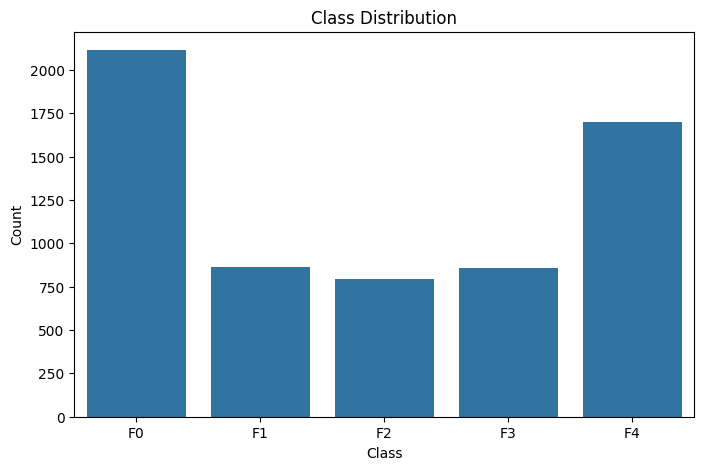

In [4]:
plt.figure(figsize=(8, 5))
sns.countplot(x=np.argmax(labels_one_hot, axis=1))
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(ticks=range(num_classes), labels=class_names)
plt.show()

## 4. Train/Validation/Test Split

In [4]:
# Train / temp split (70 / 30)
x_train, x_temp, y_train, y_temp = train_test_split(
    data,
    labels_one_hot,
    test_size=0.3,
    stratify=labels,
    random_state=42
)

# Stratify validation / test split (15 / 15)
y_temp_labels = np.argmax(y_temp, axis=1)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp_labels,
    random_state=42
)

# Shuffle
x_train, y_train = shuffle(x_train, y_train, random_state=42)
x_val, y_val = shuffle(x_val, y_val, random_state=42)
x_test, y_test = shuffle(x_test, y_test, random_state=42)

# Reshape
x_train = x_train.reshape(-1, 128, 128, 3)
x_val = x_val.reshape(-1, 128, 128, 3)
x_test = x_test.reshape(-1, 128, 128, 3)

# Confirm shapes
print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

Train shape: (4426, 128, 128, 3)
Validation shape: (948, 128, 128, 3)
Test shape: (949, 128, 128, 3)


## 5. Shared Callbacks

In [5]:
def get_callbacks(model_name):
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    )

    lr_scheduler = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )

    checkpoint = ModelCheckpoint(
        f'{model_name}-{{epoch:03d}}-{{accuracy:.3f}}-{{val_accuracy:.3f}}.keras',
        verbose=1,
        monitor='val_accuracy',
        save_best_only=True,
        mode='max'
    )
    return [checkpoint, early_stop, lr_scheduler]

## 6. Shared Evaluation Functions

In [6]:
def plot_training_history(history_data, model_name):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history_data.history['accuracy'], label='Train Accuracy')
    plt.plot(history_data.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'Model Accuracy ({model_name})')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history_data.history['loss'], label='Train Loss')
    plt.plot(history_data.history['val_loss'], label='Validation Loss')
    plt.title(f'Model Loss ({model_name})')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

def evaluate_model_performance(model, x_test, y_test, model_name):
    print(f"\n--- Evaluating {model_name} ---")
    loss, acc, prec, rec, auc_score = model.evaluate(x_test, y_test, verbose=0)
    print(f"Test Loss: {loss:.4f}")
    print(f"Test Accuracy: {acc:.4f}")
    print(f"Test Precision: {prec:.4f}")
    print(f"Test Recall: {rec:.4f}")
    print(f"Test AUC: {auc_score:.4f}")

    y_pred = model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred_classes)
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix ({model_name})')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

    # Classification Report
    report = classification_report(y_true, y_pred_classes, output_dict=True, target_names=class_names)
    df_report = pd.DataFrame(report).transpose()
    print(f"\nClassification Report ({model_name}):\n")
    print(df_report)

    # Class-wise metrics, PLR, NLR
    specificity = {}
    plr = {}
    nlr = {}
    labels_numeric = np.arange(num_classes)

    for i in labels_numeric:
        tp = conf_matrix[i, i]
        fn = np.sum(conf_matrix[i, :]) - tp
        fp = np.sum(conf_matrix[:, i]) - tp
        tn = np.sum(conf_matrix) - (tp + fp + fn)

        sens = tp / (tp + fn) if (tp + fn) > 0 else 0  # Sensitivity (Recall)
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0  # Specificity

        specificity[class_names[i]] = spec
        plr[class_names[i]] = sens / (1 - spec) if (1 - spec) > 0 else (np.inf if sens > 0 else 0)
        nlr[class_names[i]] = (1 - sens) / spec if spec > 0 else (np.inf if (1 - sens) > 0 else 0)

    print(f"\nClass-wise Metrics including PLR and NLR ({model_name}):")
    for c_name in class_names:
        print(f"  Class {c_name}:")
        print(f"    Precision   : {report[c_name]['precision']:.4f}")
        print(f"    Recall      : {report[c_name]['recall']:.4f}")
        print(f"    Specificity : {specificity[c_name]:.4f}")
        print(f"    PLR         : {plr[c_name]:.4f}")
        print(f"    NLR         : {nlr[c_name]:.4f}")
        print(f"    F1-Score    : {report[c_name]['f1-score']:.4f}")

    # ROC Curves
    y_true_bin = label_binarize(y_test, classes=np.arange(num_classes))
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(num_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    colors = plt.cm.get_cmap("tab10", num_classes)
    for i in range(num_classes):
        plt.plot(fpr[i], tpr[i], color=colors(i), lw=2, label=f'ROC curve of class {class_names[i]} (area = {roc_auc[i]:.2f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Multi-class ROC Curve ({model_name})')
    plt.legend(loc="lower right")
    plt.show()

    # Return key metrics for comparison table
    return {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_weighted': df_report.loc['weighted avg', 'f1-score'],
        'auc_overall': auc_score
    }

## 7. Shared Grad-CAM Functions

In [7]:
def find_last_conv_layer(model_to_inspect):
    """Dynamically finds the name of the last convolutional layer in a Keras model."""
    for layer in reversed(model_to_inspect.layers):
        if isinstance(layer, (tf.keras.layers.Conv2D,
                              tf.keras.layers.DepthwiseConv2D,
                              tf.keras.layers.SeparableConv2D)):
            # Heuristic to avoid 1x1 convs that might not be feature-rich for Grad-CAM
            if hasattr(layer, 'kernel_size') and layer.kernel_size == (1, 1) and 'conv' not in layer.name.lower():
                continue
            return layer.name
    return None

def get_img_array_from_tensor(img_tensor, size):
    img = tf.image.resize(img_tensor, size)
    img = tf.expand_dims(img, axis=0)
    return img

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    # Create a model that maps the input image to the activations of the last conv layer as well as the final predictions
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    # Gradient of the output class with respect to the activations of the last conv layer
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2)) # Pool the gradients
    conv_outputs = conv_outputs[0]

    # Weight the activation maps by the pooled gradients to get the heatmap
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + K.epsilon()) # Normalize heatmap
    return heatmap.numpy(), int(pred_index)

def save_and_display_gradcam_overlay(image, heatmap, alpha=0.4):
    heatmap = np.uint8(255 * heatmap)
    jet = plt.colormaps["jet"]
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = Image.fromarray((jet_heatmap * 255).astype(np.uint8))
    jet_heatmap = jet_heatmap.resize((image.shape[1], image.shape[0]))
    jet_heatmap = np.array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + image
    superimposed_img = np.uint8(superimposed_img)
    return superimposed_img

def generate_grad_cams(model, x_test, y_test, model_name, num_samples=5, img_size=(128, 128)):
    print(f"\n--- Generating Grad-CAMs for {model_name} ---")
    output_dir = f"gradcam_outputs_{model_name}"
    os.makedirs(output_dir, exist_ok=True)

    last_conv_layer_name = find_last_conv_layer(model)
    if not last_conv_layer_name:
        print(f"Warning: Could not find a suitable convolutional layer for Grad-CAM in {model_name}.")
        return

    # Create a model without the final softmax activation for Grad-CAM
    model_no_softmax = tf.keras.models.Model(
        model.inputs, model.layers[-2].output # Assuming -2 is the layer before softmax
    )

    plt.figure(figsize=(15, num_samples * 4))

    for idx in range(min(num_samples, len(x_test))):
        img = x_test[idx]
        true_label = np.argmax(y_test[idx]) if y_test.ndim == 2 else y_test[idx]

        img_array = get_img_array_from_tensor(img, img_size)

        heatmap, pred_class = make_gradcam_heatmap(img_array, model_no_softmax, last_conv_layer_name)

        img_uint8 = np.uint8(img * 255)
        superimposed_img = save_and_display_gradcam_overlay(img_uint8, heatmap)

        # Display original image
        plt.subplot(num_samples, 3, idx * 3 + 1)
        plt.imshow(img_uint8)
        plt.title(f"Original (True: {class_names[true_label]})")
        plt.axis('off')

        # Display heatmap
        plt.subplot(num_samples, 3, idx * 3 + 2)
        plt.imshow(heatmap, cmap='jet')
        plt.title("Heatmap")
        plt.axis('off')

        # Display superimposed image
        plt.subplot(num_samples, 3, idx * 3 + 3)
        plt.imshow(superimposed_img)
        plt.title(f"Grad-CAM (Pred: {class_names[pred_class]})")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

    # Zip the outputs
    zip_filename = f"gradcams_{model_name}.zip"
    shutil.make_archive(zip_filename.replace('.zip', ''), 'zip', output_dir)
    print(f"Grad-CAM images zipped into '{zip_filename}'")
    # files.download(zip_filename) # Uncomment if running in Colab and want to download automatically
    shutil.rmtree(output_dir) # Clean up directory

## 8. Shared Inference Benchmarking and Model Size Calculation

In [8]:
def benchmark_and_size_model(model, x_test, model_name):
    print(f"\n--- Benchmarking {model_name} ---")

    # Inference time
    start_inf = time.time()
    _ = model.predict(x_test, verbose=0)
    end_inf = time.time()
    inference_time = end_inf - start_inf
    ms_per_image = (inference_time / len(x_test)) * 1000
    print(f"Total inference time: {inference_time:.2f} seconds")
    print(f"Milliseconds per image: {ms_per_image:.2f} ms")

    # Save and get model size
    save_dir = f"saved_models_{model_name}"
    os.makedirs(save_dir, exist_ok=True)
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    keras_path = os.path.join(save_dir, f"{model_name}_livermodel_{timestamp}.keras")
    model.save(keras_path)
    model_size_mb = os.path.getsize(keras_path) / (1024 * 1024)
    print(f"Model size (Keras format): {model_size_mb:.2f} MB")
    shutil.rmtree(save_dir) # Clean up saved model directory

    # Parameter counting
    total_params = model.count_params()
    trainable_params = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable_params = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    print(f"Total parameters: {total_params}")
    print(f"Trainable parameters: {trainable_params}")
    print(f"Non-trainable parameters: {non_trainable_params}")

    return {
        'parameters': total_params,
        'model_size_mb': model_size_mb,
        'inference_time_ms_per_image': ms_per_image
    }

## Helper function for model building

In [9]:
def build_classifier_head(inputs, num_classes):
    x = GlobalAveragePooling2D()(inputs)
    x = Dense(512, activation="relu")(x)
    x = Dense(256, activation="relu")(x)
    outputs = Dense(num_classes, activation="softmax")(x)
    return outputs

## 9. ResNet50 Training and Evaluation

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,769,413 (94.49 MB)

 Trainable params: 24,716,293 (94.29 MB)

 Non-trainable params: 53,120 (207.50 KB)


--- Training ResNet50 ---
Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5364 - auc: 0.8384 - loss: 1.1331 - precision: 0.7152 - recall: 0.3873
Epoch 1: val_accuracy improved from None to 0.13608, saving model to resnet50-001-0.614-0.136.keras

Epoch 1: finished saving model to resnet50-001-0.614-0.136.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 115s 214ms/step - accuracy: 0.6139 - auc: 0.8921 - loss: 0.9123 - precision: 0.8044 - recall: 0.4720 - val_accuracy: 0.1361 - val_auc: 0.4333 - val_loss: 2.0258 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.7376 - auc: 0.9468 - loss: 0.6380 - precision: 0.8792 - recall: 0.6191
Epoch 2: val_accuracy improved from 0.13608 to 0.33439, saving model to resnet50-002-0.744-0.334.keras

Epoch 2: finished saving model to resnet50-002-0.744-0.334.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 27s 98ms/step - accuracy: 0.7442 - auc: 0.9497 - loss: 0.6184 - p

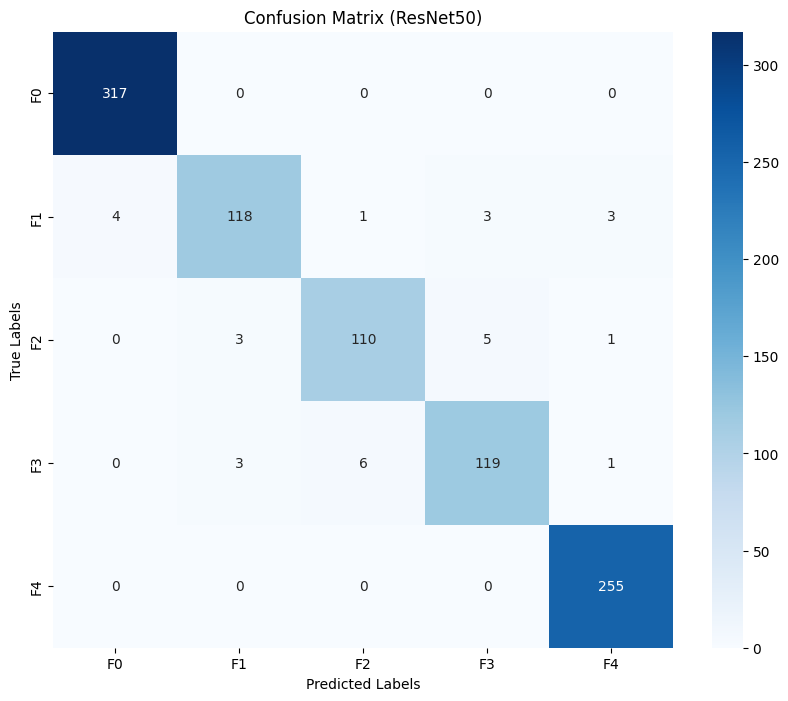


Classification Report (ResNet50):

              precision    recall  f1-score     support
F0             0.987539  1.000000  0.993730  317.000000
F1             0.951613  0.914729  0.932806  129.000000
F2             0.940171  0.924370  0.932203  119.000000
F3             0.937008  0.922481  0.929688  129.000000
F4             0.980769  1.000000  0.990291  255.000000
accuracy       0.968388  0.968388  0.968388    0.968388
macro avg      0.959420  0.952316  0.955744  949.000000
weighted avg   0.968028  0.968388  0.968104  949.000000

Class-wise Metrics including PLR and NLR (ResNet50):
  Class F0:
    Precision   : 0.9875
    Recall      : 1.0000
    Specificity : 0.9937
    PLR         : 158.0000
    NLR         : 0.0000
    F1-Score    : 0.9937
  Class F1:
    Precision   : 0.9516
    Recall      : 0.9147
    Specificity : 0.9927
    PLR         : 125.0129
    NLR         : 0.0859
    F1-Score    : 0.9328
  Class F2:
    Precision   : 0.9402
    Recall      : 0.9244
    Specificity 

/tmp/ipykernel_470/2383659246.py:88: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", num_classes)


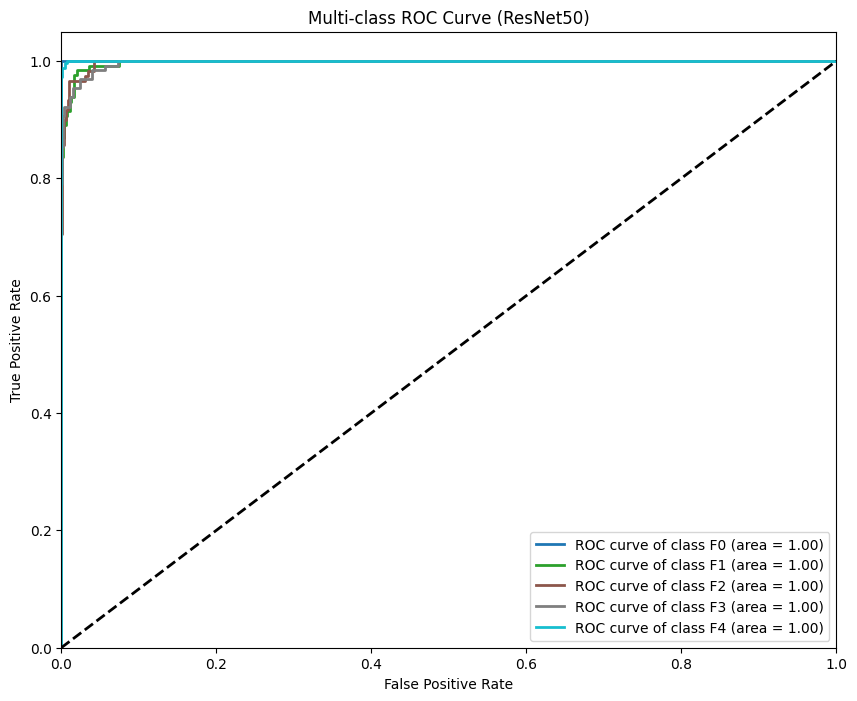

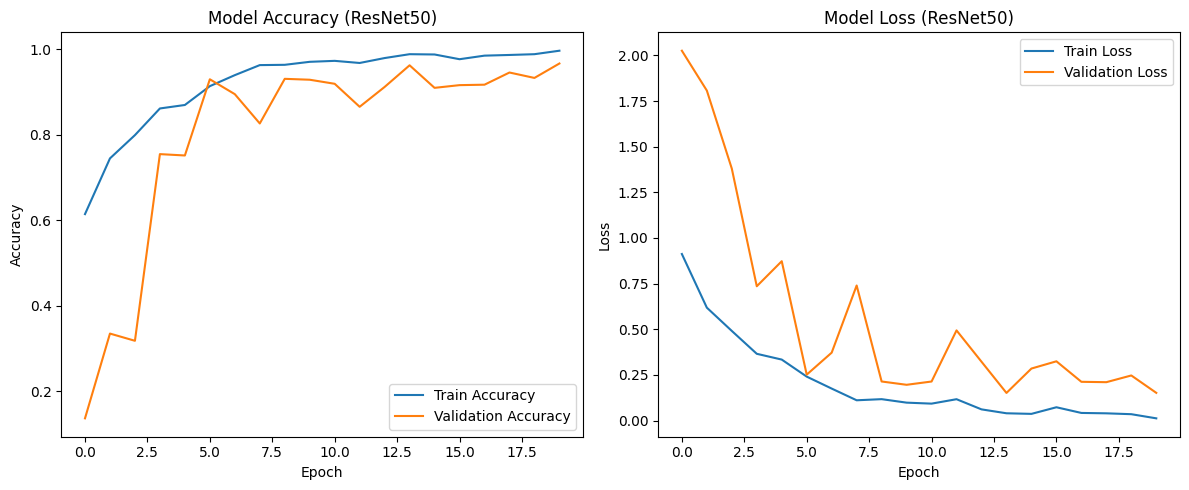


--- Benchmarking resnet50 ---
Total inference time: 1.54 seconds
Milliseconds per image: 1.63 ms
Model size (Keras format): 283.84 MB
Total parameters: 24769413
Trainable parameters: 24716293
Non-trainable parameters: 53120

--- Generating Grad-CAMs for resnet50 ---


In [10]:
# Model Definition
inputs = tf.keras.Input(shape=(128, 128, 3))
base_model_resnet50 = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)
base_model_resnet50.trainable = True
x = base_model_resnet50(inputs)
outputs_resnet50 = build_classifier_head(x, num_classes)
model_resnet50 = Model(inputs, outputs_resnet50)

# Compile
model_resnet50.compile(optimizer=LFANET_OPTIMIZER, loss='categorical_crossentropy', metrics=METRICS) # Using LFANET_OPTIMIZER
model_resnet50.summary()

# Callbacks
callbacks_resnet50 = get_callbacks('resnet50')

# Training
print("\n--- Training ResNet50 ---")
start_train_resnet50 = time.time()
history_resnet50 = model_resnet50.fit(x_train, y_train, batch_size=16, epochs=50,
                                     validation_data=(x_val, y_val), callbacks=callbacks_resnet50, verbose=1)
end_train_resnet50 = time.time()
training_time_resnet50 = end_train_resnet50 - start_train_resnet50
print(f"\nResNet50 Training time: {training_time_resnet50:.2f} seconds")

# Evaluation
metrics_resnet50 = evaluate_model_performance(model_resnet50, x_test, y_test, 'ResNet50')
plot_training_history(history_resnet50, 'ResNet50')
benchmark_metrics_resnet50 = benchmark_and_size_model(model_resnet50, x_test, 'resnet50')
generate_grad_cams(model_resnet50, x_test, y_test, 'resnet50')

results_resnet50 = {**metrics_resnet50, **benchmark_metrics_resnet50}

## 10. DenseNet121 Training and Evaluation

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,694,917 (29.35 MB)

 Trainable params: 7,611,269 (29.03 MB)

 Non-trainable params: 83,648 (326.75 KB)


--- Training DenseNet121 ---
Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.5527 - auc: 0.8474 - loss: 1.0857 - precision: 0.6960 - recall: 0.4258
Epoch 1: val_accuracy improved from None to 0.29852, saving model to densenet121-001-0.616-0.299.keras

Epoch 1: finished saving model to densenet121-001-0.616-0.299.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 301s 511ms/step - accuracy: 0.6161 - auc: 0.8909 - loss: 0.9021 - precision: 0.7829 - recall: 0.4840 - val_accuracy: 0.2985 - val_auc: 0.6291 - val_loss: 3.4948 - val_precision: 0.2970 - val_recall: 0.2532 - learning_rate: 0.0010
Epoch 2/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.6899 - auc: 0.9293 - loss: 0.7344 - precision: 0.8272 - recall: 0.5722
Epoch 2: val_accuracy improved from 0.29852 to 0.61392, saving model to densenet121-002-0.709-0.614.keras

Epoch 2: finished saving model to densenet121-002-0.709-0.614.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 23s 82ms/step - accuracy: 0.7088 - auc: 0.9364 - loss: 0.6

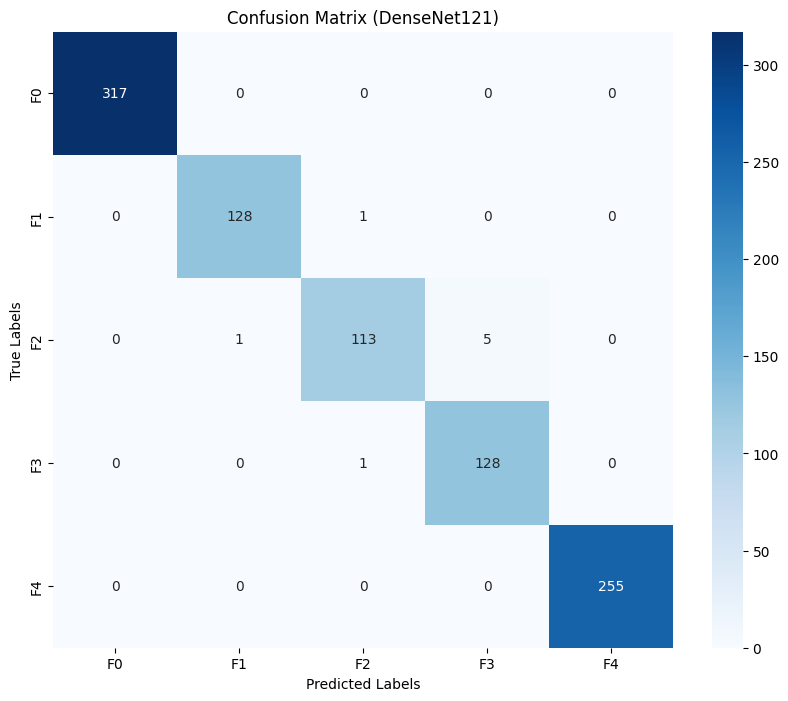


Classification Report (DenseNet121):

              precision    recall  f1-score    support
F0             1.000000  1.000000  1.000000  317.00000
F1             0.992248  0.992248  0.992248  129.00000
F2             0.982609  0.949580  0.965812  119.00000
F3             0.962406  0.992248  0.977099  129.00000
F4             1.000000  1.000000  1.000000  255.00000
accuracy       0.991570  0.991570  0.991570    0.99157
macro avg      0.987453  0.986815  0.987032  949.00000
weighted avg   0.991655  0.991570  0.991546  949.00000

Class-wise Metrics including PLR and NLR (DenseNet121):
  Class F0:
    Precision   : 1.0000
    Recall      : 1.0000
    Specificity : 1.0000
    PLR         : inf
    NLR         : 0.0000
    F1-Score    : 1.0000
  Class F1:
    Precision   : 0.9922
    Recall      : 0.9922
    Specificity : 0.9988
    PLR         : 813.6434
    NLR         : 0.0078
    F1-Score    : 0.9922
  Class F2:
    Precision   : 0.9826
    Recall      : 0.9496
    Specificity : 0.9976

/tmp/ipykernel_477/2383659246.py:88: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", num_classes)


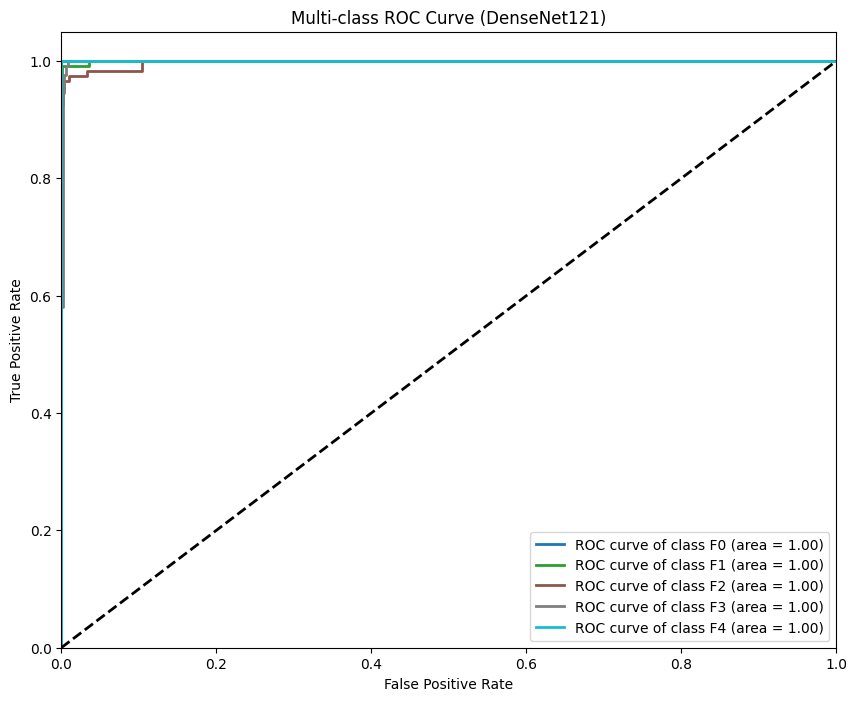

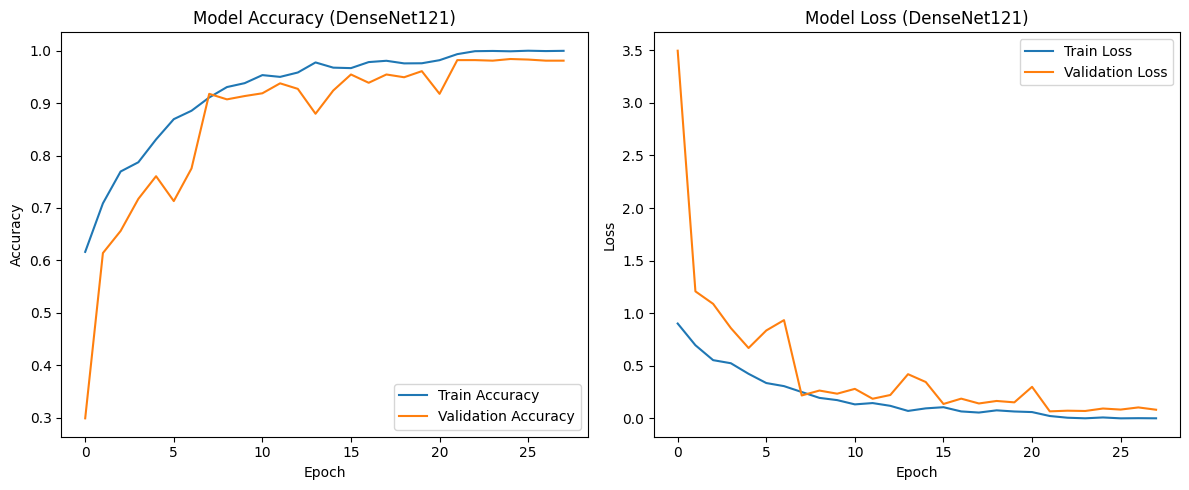


--- Benchmarking densenet121 ---
Total inference time: 1.45 seconds
Milliseconds per image: 1.53 ms
Model size (Keras format): 89.13 MB
Total parameters: 7694917
Trainable parameters: 7611269
Non-trainable parameters: 83648

--- Generating Grad-CAMs for densenet121 ---


In [10]:
# Model Definition
inputs = tf.keras.Input(shape=(128, 128, 3))
base_model_densenet121 = DenseNet121(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)
base_model_densenet121.trainable = True
x = base_model_densenet121(inputs)
outputs_densenet121 = build_classifier_head(x, num_classes)
model_densenet121 = Model(inputs, outputs_densenet121)

# Compile
model_densenet121.compile(optimizer=LFANET_OPTIMIZER, loss='categorical_crossentropy', metrics=METRICS) # Using LFANET_OPTIMIZER
model_densenet121.summary()

# Callbacks
callbacks_densenet121 = get_callbacks('densenet121')

# Training
print("\n--- Training DenseNet121 ---")
start_train_densenet121 = time.time()
history_densenet121 = model_densenet121.fit(x_train, y_train, batch_size=16, epochs=50,
                                         validation_data=(x_val, y_val), callbacks=callbacks_densenet121, verbose=1)
end_train_densenet121 = time.time()
training_time_densenet121 = end_train_densenet121 - start_train_densenet121
print(f"\nDenseNet121 Training time: {training_time_densenet121:.2f} seconds")

# Evaluation
metrics_densenet121 = evaluate_model_performance(model_densenet121, x_test, y_test, 'DenseNet121')
plot_training_history(history_densenet121, 'DenseNet121')
benchmark_metrics_densenet121 = benchmark_and_size_model(model_densenet121, x_test, 'densenet121')
generate_grad_cams(model_densenet121, x_test, y_test, 'densenet121')

results_densenet121 = {**metrics_densenet121, **benchmark_metrics_densenet121}